##Setup and Installation

In [ ]:
!pip install ultralytics

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving plastics_filtered.zip to plastics_filtered.zip


## Dataset Extraction

In [ ]:
import zipfile
import os

zip_path = '/content/plastics_filtered.zip'
extract_path = '/content/dataset'

# Extract the zip file
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("✅ Extraction complete!")


✅ Extraction complete!


##Reading data.yaml Configuration File

In [ ]:
import yaml


yaml_path = '/content/dataset/plastics_filtered/data.yaml'

# Read and print the YAML contents
with open(yaml_path, 'r') as f:
    data = yaml.safe_load(f)

print("📄 Contents of data.yaml:\n")
print(data)

📄 Contents of data.yaml:

{'names': ['Mask', 'pbag', 'pbottle'], 'nc': 3, 'test': '../test/images', 'train': '../train/images', 'val': '../valid/images'}


##Data Verification

In [ ]:
import os
import glob

def check_image_label_pairs(dataset_path):
    """
    Checks if every image has a corresponding label file and vice versa.
    """

    # Define image and label directories
    image_dir = os.path.join(dataset_path, 'images')
    label_dir = os.path.join(dataset_path, 'labels')

    # Collect image and label file names (without extensions)
    image_files = glob.glob(os.path.join(image_dir, '*.jpg')) + glob.glob(os.path.join(image_dir, '*.png'))
    label_files = glob.glob(os.path.join(label_dir, '*.txt'))

    image_names = {os.path.splitext(os.path.basename(f))[0] for f in image_files}
    label_names = {os.path.splitext(os.path.basename(f))[0] for f in label_files}

    # Find mismatches
    missing_labels = image_names - label_names
    missing_images = label_names - image_names

    # Print summary
    print(f"📁 Dataset Path: {dataset_path}")
    print(f"🖼 Total images found: {len(image_files)}")
    print(f"📝 Total label files found: {len(label_files)}")
    print(f"❌ Images without labels: {len(missing_labels)}")
    print(f"❌ Labels without images: {len(missing_images)}")

    # Optional: list few examples
    if missing_labels:
        print("\n🖼 Images missing labels (first 10):")
        print(list(missing_labels)[:10])
    if missing_images:
        print("\n📝 Labels missing images (first 10):")
        print(list(missing_images)[:10])

    return missing_labels, missing_images

In [ ]:
missing_labels, missing_images = check_image_label_pairs('/content/dataset/plastics_filtered')

📁 Dataset Path: /content/dataset/plastics_filtered
🖼 Total images found: 0
📝 Total label files found: 0
❌ Images without labels: 0
❌ Labels without images: 0


In [ ]:
import yaml
import matplotlib.pyplot as plt
from collections import Counter
import cv2
import random

yaml_path = '/content/dataset/plastics_filtered/data.yaml'

with open(yaml_path, 'r') as f:
    data = yaml.safe_load(f)

# Extract class names
class_names = data['names']
print("✅ Classes found:", class_names)


✅ Classes found: ['Mask', 'pbag', 'pbottle']


##Class Distribution (Before Balancing)

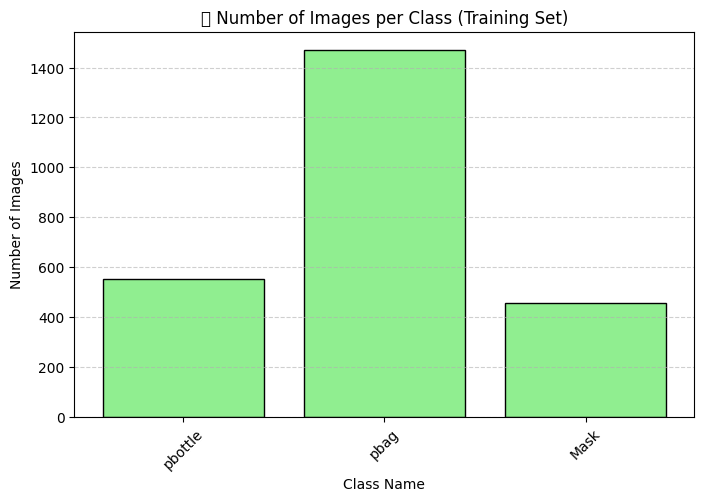

{'pbottle': 553, 'pbag': 1470, 'Mask': 456}

In [ ]:
import os
import glob
import matplotlib.pyplot as plt
from collections import defaultdict
import yaml

def plot_class_distribution_train(dataset_path, yaml_path):
    """
    Plots the number of images containing each class in the training set.
    """

    # Load class names from data.yaml
    with open(yaml_path, 'r') as f:
        data = yaml.safe_load(f)
    class_names = data['names']

    # Path to training labels
    label_path = os.path.join(dataset_path, 'train/labels')
    label_files = glob.glob(os.path.join(label_path, '*.txt'))

    # Count how many images contain each class
    class_to_images = defaultdict(set)
    for file in label_files:
        image_id = os.path.splitext(os.path.basename(file))[0]
        with open(file, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) > 0:
                    cls_id = int(parts[0])
                    class_to_images[cls_id].add(image_id)

    # Prepare data for plotting
    class_counts = {class_names[i]: len(imgs) for i, imgs in class_to_images.items()}

    # Plot
    plt.figure(figsize=(8,5))
    plt.bar(class_counts.keys(), class_counts.values(), color='lightgreen', edgecolor='black')
    plt.title("📊 Number of Images per Class (Training Set)")
    plt.xlabel("Class Name")
    plt.ylabel("Number of Images")
    plt.xticks(rotation=45)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    plt.show()

    return class_counts

# === Run for your dataset ===
plot_class_distribution_train(
    dataset_path='/content/dataset/plastics_filtered',
    yaml_path='/content/dataset/plastics_filtered/data.yaml'
)


## Data Balancing and Augmentation


In [ ]:
import random
import shutil
from PIL import Image, ImageOps, ImageEnhance
from tqdm import tqdm

# === Paths ===
base_path = '/content/dataset/plastics_filtered'
train_images_dir = os.path.join(base_path, 'train/images')
train_labels_dir = os.path.join(base_path, 'train/labels')

# Output path (new balanced folder)
output_images_dir = os.path.join(base_path, 'train_balanced/images')
output_labels_dir = os.path.join(base_path, 'train_balanced/labels')
os.makedirs(output_images_dir, exist_ok=True)
os.makedirs(output_labels_dir, exist_ok=True)

# === Desired number of images per class ===
TARGET = 650

# === Helper function: Augmentation ===
def augment_image(img_path, output_dir, aug_name):
    """Simple augmentations: flip, rotate, brightness."""
    img = Image.open(img_path)

    if random.random() > 0.5:
        img = ImageOps.mirror(img)  # horizontal flip
    if random.random() > 0.5:
        img = img.rotate(random.choice([90, 180, 270]))
    if random.random() > 0.5:
        enhancer = ImageEnhance.Brightness(img)
        img = enhancer.enhance(random.uniform(0.7, 1.3))

    aug_path = os.path.join(output_dir, f"{aug_name}.jpg")
    img.save(aug_path, quality=95)

# === Step 1: Group images by class ===
class_to_images = defaultdict(list)
for lbl_file in glob.glob(os.path.join(train_labels_dir, '*.txt')):
    with open(lbl_file, 'r') as f:
        lines = f.readlines()
        if not lines:
            continue
        cls_id = int(lines[0].split()[0])  # assumes one class per image
        class_to_images[cls_id].append(os.path.splitext(os.path.basename(lbl_file))[0])

print("📊 Class distribution before balancing:")
for cls, imgs in class_to_images.items():
    print(f"Class {cls}: {len(imgs)} images")

# === Step 2: Create balanced dataset ===
for cls_id, images in class_to_images.items():
    print(f"\n⚙️ Processing class {cls_id} ...")
    if len(images) >= TARGET:
        # Randomly select TARGET images
        selected = random.sample(images, TARGET)
    else:
        selected = images.copy()

    # Copy selected images
    for name in selected:
        img_src = os.path.join(train_images_dir, f"{name}.jpg")
        lbl_src = os.path.join(train_labels_dir, f"{name}.txt")
        if os.path.exists(img_src) and os.path.exists(lbl_src):
            shutil.copy(img_src, output_images_dir)
            shutil.copy(lbl_src, output_labels_dir)

    # Augment if needed
    if len(images) < TARGET:
        needed = TARGET - len(images)
        augment_candidates = random.choices(images, k=needed)
        for name in tqdm(augment_candidates, desc=f"Augmenting class {cls_id}"):
            img_src = os.path.join(train_images_dir, f"{name}.jpg")
            lbl_src = os.path.join(train_labels_dir, f"{name}.txt")

            aug_name = f"{name}_aug{random.randint(0,9999)}"
            augment_image(img_src, output_images_dir, aug_name)
            shutil.copy(lbl_src, os.path.join(output_labels_dir, f"{aug_name}.txt"))

print("\n✅ Balancing complete!")
print(f"Saved to:\n{output_images_dir}\n{output_labels_dir}")

📊 Class distribution before balancing:
Class 2: 535 images
Class 1: 1450 images
Class 0: 456 images

⚙️ Processing class 2 ...


Augmenting class 2: 100%|██████████| 115/115 [00:00<00:00, 139.72it/s]



⚙️ Processing class 1 ...

⚙️ Processing class 0 ...


Augmenting class 0: 100%|██████████| 194/194 [00:00<00:00, 309.47it/s]


✅ Balancing complete!
Saved to:
/content/dataset/plastics_filtered/train_balanced/images
/content/dataset/plastics_filtered/train_balanced/labels


## Visualizing Class Distribution (After Balancing)



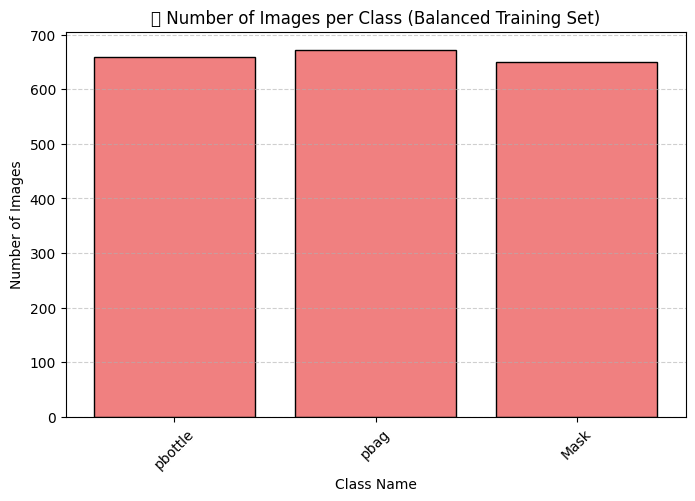


✅ Class Counts in Balanced Dataset:
{'pbottle': 660, 'pbag': 672, 'Mask': 650}


In [ ]:
import os, glob, yaml, matplotlib.pyplot as plt
from collections import defaultdict

def plot_class_distribution_balanced(dataset_path, yaml_path):
    """
    Plots the number of images containing each class in the *balanced* training set.
    """
    with open(yaml_path, 'r') as f:
        data = yaml.safe_load(f)
    class_names = data['names']

    label_path = os.path.join(dataset_path, 'train_balanced/labels')
    label_files = glob.glob(os.path.join(label_path, '*.txt'))

    class_to_images = defaultdict(set)
    for file in label_files:
        image_id = os.path.splitext(os.path.basename(file))[0]
        with open(file, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) > 0:
                    cls_id = int(parts[0])
                    class_to_images[cls_id].add(image_id)

    class_counts = {class_names[i]: len(imgs) for i, imgs in class_to_images.items()}

    plt.figure(figsize=(8,5))
    plt.bar(class_counts.keys(), class_counts.values(), color='lightcoral', edgecolor='black')
    plt.title("📊 Number of Images per Class (Balanced Training Set)")
    plt.xlabel("Class Name")
    plt.ylabel("Number of Images")
    plt.xticks(rotation=45)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    plt.show()

    print("\n✅ Class Counts in Balanced Dataset:")
    print(class_counts)

# === Run for your balanced dataset ===
plot_class_distribution_balanced(
    dataset_path='/content/dataset/plastics_filtered',
    yaml_path='/content/dataset/plastics_filtered/data.yaml'
)

## Model Training (YOLOv8 Nano, Medium, Large)